In [24]:
import polars as pl

In [25]:
data_raw = pl.read_csv("https://github.com/unit8co/darts/raw/refs/heads/master/datasets/taxi_new_york_passengers.csv", try_parse_dates=True)
data = (
    data_raw
    .rename({"#Passengers": "pas"})
)
data.columns, data.shape

(['time', 'pas'], (10320, 2))

In [26]:
from futureish.datapoints import RecordedDataPoint

# create a RecordedDataPoint for a column in the raw data and mark it as not known in the future
pas_dp = RecordedDataPoint(name="pas", step_size="30m", known_future=False) 

In [27]:
from futureish.features import RecordedInputFeature, BusinessDayFeature, SinCosTimeFeature
from futureish.scaling import DiffScaler, ZScoreScaler, ChainedScaler

input_features = [
    # create a RecordedInputFeature based on the RecordedDataPoint, including the last 2 hours of data as input, and apply a chain of scalers (differencing followed by z-score normalization)
    RecordedInputFeature(pas_dp, feature_name="pas_lags", input_length="2h", scaler_factory=ChainedScaler.from_scalers(DiffScaler, ZScoreScaler)),
    # add a business day feature indicating if the current and the previous 3 days are business days
    BusinessDayFeature(day_history=3),
    # include hour and weekday information as sine and cosine transformations to capture cyclical time patterns in the data
    SinCosTimeFeature(hour=True, weekday=True)
]

In [28]:
from futureish.features import TargetFeature
target_features = [
    # create a TargetFeature that predicts the RecordedDataPoint with a chain of scalers (differencing followed by z-score normalization)
    TargetFeature(pas_dp, feature_name="pas_feature", scaler_factory=ChainedScaler.from_scalers(DiffScaler, ZScoreScaler))
]

In [29]:
from futureish.datasets import Dataset

# Create a Dataset object with the raw data, input features, and target features
dataset = Dataset(
    raw_data=data,
    input_features=input_features,
    target_features=target_features,
)
# Split the dataset into training and test sets, using 80% of the data for training and 20% for testing
train_dataset, test_dataset = dataset.split_training_and_test_data(0.8)

In [30]:
from futureish.gpr import GPyTorchOnlinePEP, GPyTorchFitConfig
from futureish.forecasting import Forecaster
import torch

# create a forecaster (which conveninience functions) with an underlying model
# use GPyTorchOnlinePEP as a underlying model and wrapping it to be compatible with the forecaster
# the numer of inducing points is set to 100
model = Forecaster(GPyTorchOnlinePEP.wrapped(100, use_cuda=torch.cuda.is_available()))

In [31]:
model.fit(train_dataset, config=GPyTorchFitConfig(time_limit=60)) # train for 60 seconds

Iteration 1305: LR = 0.001
Iteration 1326: LR = 0.0001
Iteration 1347: LR = 1e-05
Iteration 1368: LR = 1.0000000000000002e-06
Iteration 1389: LR = 1.0000000000000002e-07
Iteration 1410: LR = 1.0000000000000004e-08


In [32]:
traj_data, ground_truth = test_dataset.create_prediction_trajectory(t0_offset="6h", pred_len="1d") # create a single trajectory for prediction starting 6 hours after the start of the test dataset and predicting for 2 days
traj = model.predict_autoregressive(traj_data) # make an autoregressive prediction using the model on the trajectory data

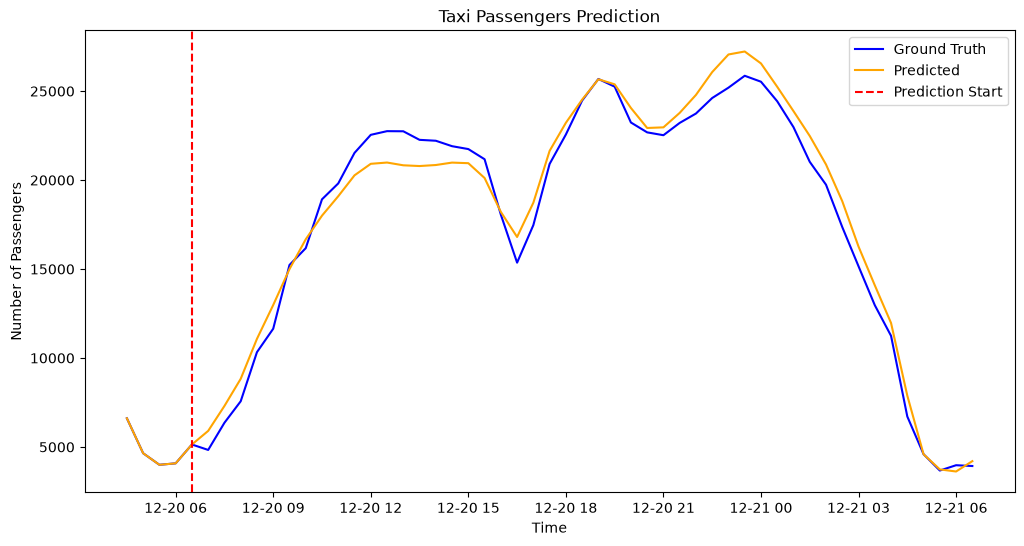

In [33]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
plt.plot(ground_truth["time"], ground_truth["pas"], label="Ground Truth", color="blue")
plt.plot(traj["time"], traj["pas"], label="Predicted", color="orange")
plt.axvline(traj.select(pl.col("t0").drop_nulls().first()).item(), color="red", linestyle="--", label="Prediction Start")
plt.xlabel("Time")
plt.ylabel("Number of Passengers")
plt.title("Taxi Passengers Prediction")
plt.legend()

In [34]:
traj_sampled = model.predict_autoregressive(traj_data, samples=100) # make an autoregressive prediction using the model on the trajectory data, but this time with 100 samples to capture uncertainty in the predictions

In [ ]:
# Compute quantiles for the sampled predictions to visualize uncertainty
traj_quantiles = (
    traj_sampled
    .group_by("time")
    .agg([
        pl.col("pas").quantile(0.1).alias("pas_10th_percentile"),
        pl.col("pas").quantile(0.5).alias("pas_median"),
        pl.col("pas").quantile(0.9).alias("pas_90th_percentile")
    ])
    .sort("time")
)

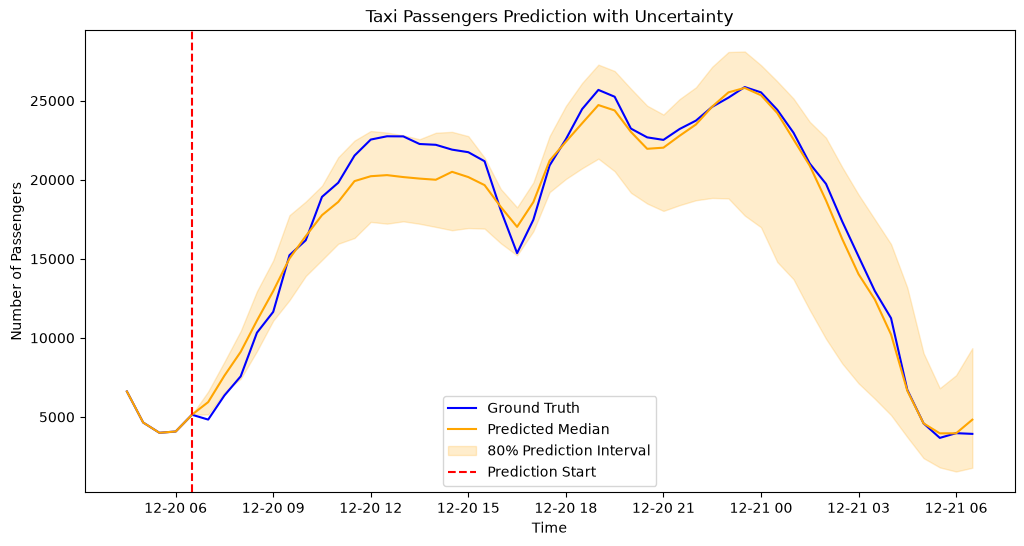

In [36]:
plt.figure(figsize=(12, 6))
plt.plot(ground_truth["time"], ground_truth["pas"], label="Ground Truth", color="blue")
plt.plot(traj_quantiles["time"], traj_quantiles["pas_median"], label="Predicted Median", color="orange")
plt.fill_between(traj_quantiles["time"], traj_quantiles["pas_10th_percentile"], traj_quantiles["pas_90th_percentile"], color="orange", alpha=0.2, label="80% Prediction Interval")
plt.axvline(traj.select(pl.col("t0").drop_nulls().first()).item(), color="red", linestyle="--", label="Prediction Start")
plt.xlabel("Time")
plt.ylabel("Number of Passengers")
plt.title("Taxi Passengers Prediction with Uncertainty")
plt.legend()